# P3 — Global LightGBM Quantile Forecasting

Huấn luyện LightGBM global trên mẫu 3.474 chuỗi, 3 rolling windows và 9 mức quantile.

- Input: `data/processed/data_long.parquet`, `common/{config.yaml,rolling_windows.csv,sample_ids.csv}`
- Output chính: `data/outputs/forecasts/lgbm.parquet`
- Output hỗ trợ: validation forecast, feature importance, runtime và run config trong `data/outputs/p3/`
- Calibration chung được thực hiện ở P5.

In [1]:
# Thiết lập môi trường và cấu hình chung
from pathlib import Path
import gc, json, platform, random, time, warnings

import lightgbm as lgb
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore")
CWD = Path.cwd()
ROOT = CWD if (CWD / "common/config.yaml").exists() else CWD.parent
assert (ROOT / "common/config.yaml").exists(), f"Không xác định được project root từ {CWD}"

with open(ROOT / "common/config.yaml", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

SEED = int(CFG["seed"]); H = int(CFG["horizon"])
Q = sorted(float(q) for q in CFG["quantiles"])
random.seed(SEED); np.random.seed(SEED)

PATH_LONG = ROOT / "data/processed/data_long.parquet"
PATH_WINDOWS = ROOT / "common/rolling_windows.csv"
PATH_SAMPLE = ROOT / "common/sample_ids.csv"
FORECAST_DIR = ROOT / "data/outputs/forecasts"
P3_OUT = ROOT / "data/outputs/p3"

for name, path in {"data_long": PATH_LONG, "rolling_windows": PATH_WINDOWS, "sample_ids": PATH_SAMPLE}.items():
    assert path.exists(), f"Thiếu {name}: {path}"

print("Python:", platform.python_version(), "| LightGBM:", lgb.__version__)
print("Project root:", ROOT)

Python: 3.11.4 | LightGBM: 4.7.0
Project root: D:\Master\Project 2


In [2]:
# Nạp đúng các cột P3 cần dùng
windows = pd.read_csv(PATH_WINDOWS)
sample_ids = pd.read_csv(PATH_SAMPLE)["series_id"].astype(str)

INPUT_COLS = ["series_id", "date", "d_int", "sales", "wday", "month",
              "is_event", "snap", "sell_price", "segment"]
data = pd.read_parquet(PATH_LONG, columns=INPUT_COLS)
data["date"] = pd.to_datetime(data["date"])
data["series_id"] = data["series_id"].astype("category")
data["segment"] = data["segment"].astype("category")
data["d_int"] = pd.to_numeric(data["d_int"]).astype("int32")
data["sales"] = pd.to_numeric(data["sales"]).astype("float32")
data = data.sort_values(["series_id", "d_int"]).reset_index(drop=True)

print("data_long:", data.shape, "| sample ids:", len(sample_ids), "| windows:", len(windows))
display(windows)

data_long: (6743034, 10) | sample ids: 3474 | windows: 3


,window,train_end,val_end,test_start,test_end
0,W1,1885,1913,1914,1941
1,W2,1857,1885,1886,1913
2,W3,1829,1857,1858,1885


In [3]:
# Kiểm tra input contract
expected_ids = set(sample_ids)
actual_ids = set(data["series_id"].astype(str).unique())
assert actual_ids == expected_ids, "data_long không khớp common/sample_ids.csv"
assert data.duplicated(["series_id", "d_int"]).sum() == 0
assert data["d_int"].min() == 1 and data["d_int"].max() == int(CFG["split"]["test_end"])
assert data.groupby("series_id", observed=True).size().nunique() == 1
assert data.groupby("d_int")["date"].nunique().max() == 1
assert len(windows) >= 3 and len(Q) == 9

N_SERIES = len(actual_ids)
segment_counts = data[["series_id", "segment"]].drop_duplicates()["segment"].value_counts()
print(f"Input hợp lệ: {N_SERIES:,} chuỗi × {data['d_int'].nunique():,} ngày")
display(segment_counts)

Input hợp lệ: 3,474 chuỗi × 1,941 ngày


segment
intermittent    1000
lumpy           1000
smooth           980
erratic          494
Name: count, dtype: int64

## Feature engineering

Các feature từ sales đều lùi ít nhất 28 ngày để toàn bộ horizon được tính từ thông tin đã biết; calendar, SNAP, event và giá là biến ngoại sinh.

In [4]:
# Tạo lag, rolling, days-since-last-sale và biến ngoại sinh
t_feature = time.perf_counter()
sales_group = data.groupby("series_id", observed=True, sort=False)["sales"]
for lag in (28, 35, 56):
    data[f"lag_{lag}"] = sales_group.shift(lag).astype("float32")

shifted_28 = sales_group.shift(H)
shifted_group = shifted_28.groupby(data["series_id"], observed=True, sort=False)
data["rmean_7"] = shifted_group.transform(lambda s: s.rolling(7, min_periods=2).mean()).astype("float32")
data["rmean_28"] = shifted_group.transform(lambda s: s.rolling(28, min_periods=5).mean()).astype("float32")
data["rstd_28"] = shifted_group.transform(lambda s: s.rolling(28, min_periods=5).std()).astype("float32")

last_sale_day = data["d_int"].where(data["sales"].gt(0)).groupby(data["series_id"], observed=True).ffill()
days_since_sale = (data["d_int"] - last_sale_day).fillna(data["d_int"]).astype("float32")
data["dsls_28"] = days_since_sale.groupby(data["series_id"], observed=True).shift(H).astype("float32")

data["price_missing"] = data["sell_price"].isna().astype("int8")
data["price_chg"] = (data.groupby("series_id", observed=True, sort=False)["sell_price"]
                           .pct_change(fill_method=None).replace([np.inf, -np.inf], 0).fillna(0).astype("float32"))
data["sell_price"] = data["sell_price"].fillna(0).astype("float32")
for c in ["wday", "month", "is_event", "snap"]:
    data[c] = data[c].fillna(0).astype("int8")

FEATURE_COLS = ["lag_28", "lag_35", "lag_56", "rmean_7", "rmean_28", "rstd_28",
                "dsls_28", "wday", "month", "is_event", "snap",
                "sell_price", "price_chg", "price_missing"]
CAT_COLS = ["wday", "month"]
print(f"Đã tạo {len(FEATURE_COLS)} features trong {time.perf_counter()-t_feature:.1f}s")

Đã tạo 14 features trong 4.4s


In [5]:
# Audit feature và cấu hình LightGBM
usable = data["lag_56"].notna()
nulls = data.loc[usable, FEATURE_COLS].isna().sum()
assert nulls.sum() == 0, f"Feature còn NA:\n{nulls[nulls > 0]}"

for _, w in windows.iterrows():
    tr, ve, ts, te = map(int, [w.train_end, w.val_end, w.test_start, w.test_end])
    assert ve - tr == H and te - ts + 1 == H and ts == ve + 1

BASE_PARAMS = dict(
    objective="quantile", metric="quantile", learning_rate=0.05,
    num_leaves=63, min_data_in_leaf=100, feature_fraction=0.8,
    bagging_fraction=0.8, bagging_freq=1, verbosity=-1, num_threads=4,
    seed=SEED, feature_fraction_seed=SEED, bagging_seed=SEED,
)
MAX_ROUNDS = 300
EARLY_STOPPING_ROUNDS = 30
FORECAST_COLS = ["series_id", "date", "d_int", "quantile_level", "value", "model"]
print("Feature audit đạt | 3 windows × 9 quantiles = 27 models")

Feature audit đạt | 3 windows × 9 quantiles = 27 models


## Rolling-origin training

Mỗi window dùng train để học, validation để early stopping và lưu forecast phục vụ calibration, test để đánh giá. Quantile crossing được xử lý bằng monotone rearrangement.

In [6]:
# Hàm huấn luyện một rolling window và check forecast cuối
def to_long_forecast(base, prediction_matrix, model_name, window_name=None):
    prediction_matrix = np.sort(np.clip(prediction_matrix, 0, None), axis=1)
    out = base.loc[base.index.repeat(len(Q))].reset_index(drop=True).copy()
    out["series_id"] = out["series_id"].astype(str)
    out["quantile_level"] = np.tile(Q, len(base))
    out["value"] = prediction_matrix.reshape(-1).astype("float32")
    out["model"] = model_name
    if window_name is not None:
        out["window"] = window_name
    return out

def train_window(w):
    window_name = str(w["window"])
    train_end, val_end = int(w["train_end"]), int(w["val_end"])
    test_start, test_end = int(w["test_start"]), int(w["test_end"])
    train_mask = (data["d_int"] <= train_end) & data["lag_56"].notna()
    val_mask = data["d_int"].between(train_end + 1, val_end)
    test_mask = data["d_int"].between(test_start, test_end)

    X_train, y_train = data.loc[train_mask, FEATURE_COLS], data.loc[train_mask, "sales"]
    X_val, y_val = data.loc[val_mask, FEATURE_COLS], data.loc[val_mask, "sales"]
    X_test = data.loc[test_mask, FEATURE_COLS]
    val_base = data.loc[val_mask, ["series_id", "date", "d_int"]].reset_index(drop=True)
    test_base = data.loc[test_mask, ["series_id", "date", "d_int"]].reset_index(drop=True)
    assert len(val_base) == N_SERIES * H and len(test_base) == N_SERIES * H

    dtrain = lgb.Dataset(X_train, label=y_train, categorical_feature=CAT_COLS, free_raw_data=False)
    dval = lgb.Dataset(X_val, label=y_val, categorical_feature=CAT_COLS, reference=dtrain, free_raw_data=False)
    val_preds, test_preds, runtime_rows, importance_rows = [], [], [], []
    print(f"{window_name}: train={len(X_train):,} | val={len(X_val):,} | test={len(X_test):,}")

    for q in Q:
        t0 = time.perf_counter()
        model = lgb.train(
            {**BASE_PARAMS, "alpha": q}, dtrain, num_boost_round=MAX_ROUNDS,
            valid_sets=[dval], valid_names=["validation"],
            callbacks=[lgb.early_stopping(EARLY_STOPPING_ROUNDS, verbose=False), lgb.log_evaluation(0)],
        )
        best_iteration = int(model.best_iteration or MAX_ROUNDS)
        val_preds.append(np.clip(model.predict(X_val, num_iteration=best_iteration), 0, None))
        test_preds.append(np.clip(model.predict(X_test, num_iteration=best_iteration), 0, None))
        seconds = time.perf_counter() - t0
        runtime_rows.append({"window": window_name, "quantile_level": q,
                             "best_iteration": best_iteration, "seconds": seconds})
        if np.isclose(q, 0.5):
            importance_rows.extend({"window": window_name, "feature": feature, "gain": float(gain)}
                                   for feature, gain in zip(FEATURE_COLS, model.feature_importance("gain")))
        print(f"  q={q:>5}: iter={best_iteration:>3} | {seconds:6.1f}s")

    val_fc = to_long_forecast(val_base, np.column_stack(val_preds), "lgbm", window_name)
    test_fc = to_long_forecast(test_base, np.column_stack(test_preds), "lgbm")
    return (test_fc[FORECAST_COLS], val_fc[FORECAST_COLS + ["window"]],
            pd.DataFrame(runtime_rows), pd.DataFrame(importance_rows))

def validate_forecast(df):
    expected_rows = len(windows) * N_SERIES * H * len(Q)
    assert list(df.columns) == FORECAST_COLS
    assert len(df) == expected_rows, f"{len(df):,} != {expected_rows:,}"
    assert df["series_id"].nunique() == N_SERIES
    assert set(np.round(df["quantile_level"].unique(), 6)) == set(np.round(Q, 6))
    assert df["value"].notna().all() and np.isfinite(df["value"]).all() and (df["value"] >= 0).all()
    assert set(df["model"].unique()) == {"lgbm"}
    assert df.duplicated(["series_id", "d_int", "quantile_level"]).sum() == 0
    wide = df.pivot(index=["series_id", "d_int"], columns="quantile_level", values="value")[Q]
    assert not (np.diff(wide.to_numpy(), axis=1) < -1e-8).any(), "Còn quantile crossing"
    print(f"Forecast hợp lệ: {len(df):,} dòng | {N_SERIES:,} chuỗi | không crossing")

In [7]:
# Huấn luyện 9 quantile trên 3 rolling window
test_parts, val_parts, runtime_parts, importance_parts = [], [], [], []
for _, window in windows.iterrows():
    test_fc, val_fc, runtime_df, importance_df = train_window(window)
    test_parts.append(test_fc); val_parts.append(val_fc)
    runtime_parts.append(runtime_df); importance_parts.append(importance_df)
    gc.collect()

fc = pd.concat(test_parts, ignore_index=True)
validation_fc = pd.concat(val_parts, ignore_index=True)
runtime = pd.concat(runtime_parts, ignore_index=True)
feature_importance = pd.concat(importance_parts, ignore_index=True)

W1: train=6,353,946 | val=97,272 | test=97,272


  q=0.005: iter=  1 |   10.6s


  q=0.025: iter=103 |   28.6s


  q=0.165: iter=291 |   63.3s


  q= 0.25: iter=265 |   65.4s


...

  q=  0.5: iter=137 |   37.2s


  q= 0.75: iter=300 |   56.9s


  q=0.835: iter=286 |   54.5s


  q=0.975: iter=197 |   43.6s


  q=0.995: iter=147 |   33.7s


In [8]:
# Check kết quả và ghi file
validate_forecast(fc)
assert len(validation_fc) == len(windows) * N_SERIES * H * len(Q)
assert validation_fc.duplicated(["window", "series_id", "d_int", "quantile_level"]).sum() == 0

feature_importance["gain_share"] = feature_importance.groupby("window")["gain"].transform(
    lambda s: s / s.sum() if s.sum() else 0
)
runtime_summary = runtime.groupby("window", as_index=False).agg(
    seconds=("seconds", "sum"), mean_best_iteration=("best_iteration", "mean")
)
display(runtime_summary)
display(feature_importance.groupby("feature", as_index=False)["gain_share"].mean()
        .sort_values("gain_share", ascending=False).head(10))

Forecast hợp lệ: 2,626,344 dòng | 3,474 chuỗi | không crossing


,window,seconds,mean_best_iteration
0,W1,453.254335,233.444444
1,W2,406.418278,178.888889
2,W3,380.709017,185.666667


,feature,gain_share
8,rmean_28,0.657889
10,rstd_28,0.179247
9,rmean_7,0.066363
11,sell_price,0.062177
7,price_missing,0.011150
0,dsls_28,0.009862
13,wday,0.003562
4,lag_56,0.002695
5,month,0.002628
2,lag_28,0.002319


In [9]:
# Lưu output và artifact
FORECAST_DIR.mkdir(parents=True, exist_ok=True)
P3_OUT.mkdir(parents=True, exist_ok=True)
fc.to_parquet(FORECAST_DIR / "lgbm.parquet", index=False)
validation_fc.to_parquet(P3_OUT / "lgbm_validation.parquet", index=False)
feature_importance.to_parquet(P3_OUT / "lgbm_feature_importance.parquet", index=False)
runtime.to_csv(P3_OUT / "lgbm_runtime.csv", index=False)

run_config = {
    "python": platform.python_version(), "lightgbm": lgb.__version__, "seed": SEED,
    "horizon": H, "quantiles": Q, "n_series": N_SERIES,
    "n_windows": len(windows), "features": FEATURE_COLS,
    "categorical_features": CAT_COLS, "max_rounds": MAX_ROUNDS,
    "early_stopping_rounds": EARLY_STOPPING_ROUNDS, "params": BASE_PARAMS,
}
with open(P3_OUT / "lgbm_run_config.json", "w", encoding="utf-8") as f:
    json.dump(run_config, f, ensure_ascii=False, indent=2)

print("Đã lưu:", FORECAST_DIR / "lgbm.parquet")
print("Forecast rows:", f"{len(fc):,}", "| runtime:", f"{runtime['seconds'].sum()/60:.1f} phút")

Đã lưu: D:\Master\Project 2\data\outputs\forecasts\lgbm.parquet
Forecast rows: 2,626,344 | runtime: 20.7 phút


## Mô hình cổ điển cho nhu cầu gián đoạn (Bước 5 · phần còn lại của P3)

Naive & SeasonalNaive(7) làm mốc; **Croston / SBA / TSB** (statsforecast) chuyên trị chuỗi gián đoạn.
Các mô hình này chỉ cho **giá trị điểm** → bọc phân phối **Negative Binomial** (dispersion theo chuỗi
từ insample: `r = m²/(v−m)` nếu `v>m`, ngược lại Poisson) để sinh đủ 9 quantile — cùng spec với TTM ở P4.

Mỗi cửa sổ rolling: **test** fit trên lịch sử `d_int ≤ test_start−1`, **val** fit trên `d_int ≤ train_end`
(out-of-sample, để P5 hiệu chuẩn conformal). Cả hai đều dự báo 1..28 bước, tôn trọng trục thời gian.
Dùng lại `data`, `windows`, `sample_ids`, `N_SERIES`, `Q`, `H`, `FORECAST_COLS`, `FORECAST_DIR` ở trên.


In [10]:
# <<P3-CLASSICAL>> Helpers: dispersion NB, bung point->9 quantile, sinh point 5 mô hình cổ điển
from scipy import stats
from statsforecast import StatsForecast
from statsforecast.models import CrostonClassic, CrostonSBA, TSB

CLASSICAL = ["naive", "snaive", "croston", "sba", "tsb"]
DAY_TO_DATE = data[["d_int", "date"]].drop_duplicates().set_index("d_int")["date"].to_dict()
DATE_TO_DAY = {v: k for k, v in DAY_TO_DATE.items()}
SALES = data[["series_id", "date", "d_int", "sales"]].copy()
SALES["series_id"] = SALES["series_id"].astype(str)

def nb_dispersion(origin):
    mv = SALES.loc[SALES["d_int"] <= origin].groupby("series_id")["sales"].agg(["mean", "var"])
    mean, var = mv["mean"].to_numpy(), mv["var"].to_numpy()
    r = np.full(len(mv), np.inf)
    use = (mean > 0) & (var > mean)
    r[use] = mean[use] ** 2 / (var[use] - mean[use])
    return dict(zip(mv.index, r))

def point_to_quantiles(point_df, model_name, disp_r):
    """point_df[series_id,date,d_int,value(mean)] -> long 9 quantile theo NB/Poisson."""
    pf = point_df.copy()
    pf["value"] = pf["value"].clip(lower=0).astype(float)
    pf["r"] = pf["series_id"].map(disp_r).fillna(np.inf)
    mu, r = pf["value"].to_numpy(), pf["r"].to_numpy()
    finite = np.isfinite(r) & (r > 0)
    out = []
    for q in Q:
        qv = np.empty_like(mu, dtype=float)
        if finite.any():
            rr, mm = r[finite], mu[finite]
            qv[finite] = stats.nbinom.ppf(q, rr, rr / (rr + np.where(mm > 0, mm, 1e-9)))
        if (~finite).any():
            qv[~finite] = stats.poisson.ppf(q, mu[~finite])
        blk = pf[["series_id", "date", "d_int"]].copy()
        blk["quantile_level"] = float(q)
        blk["value"] = np.nan_to_num(qv, nan=0.0, posinf=0.0, neginf=0.0)
        blk["model"] = model_name
        out.append(blk)
    return pd.concat(out, ignore_index=True)[FORECAST_COLS]

def classical_points(origin):
    """Point forecast 5 mô hình cổ điển fit trên d_int<=origin, dự báo origin+1..origin+H (phẳng theo thời gian)."""
    ins = SALES.loc[SALES["d_int"] <= origin].sort_values(["series_id", "d_int"])
    days = np.arange(origin + 1, origin + 1 + H)
    date_arr = [DAY_TO_DATE[d] for d in days]
    pts = {}
    last = ins.groupby("series_id")["sales"].last()
    pts["naive"] = pd.DataFrame(
        [(sid, dt, int(d), float(last.get(sid, 0.0))) for sid in sample_ids for d, dt in zip(days, date_arr)],
        columns=["series_id", "date", "d_int", "value"])
    def _tile(s):
        v = s.to_numpy()[-7:]
        if len(v) < 7:
            v = np.pad(v, (7 - len(v), 0))
        return np.tile(v, int(np.ceil(H / 7)))[:H]
    smap = ins.groupby("series_id")["sales"].apply(_tile).to_dict()
    pts["snaive"] = pd.DataFrame(
        [(sid, dt, int(d), float(v)) for sid in sample_ids
         for d, dt, v in zip(days, date_arr, smap.get(sid, np.zeros(H)))],
        columns=["series_id", "date", "d_int", "value"])
    sf_train = ins.rename(columns={"series_id": "unique_id", "date": "ds", "sales": "y"})[["unique_id", "ds", "y"]]
    sf = StatsForecast(models=[CrostonClassic(), CrostonSBA(), TSB(alpha_d=0.2, alpha_p=0.2)], freq="D", n_jobs=1)
    fcst = sf.forecast(h=H, df=sf_train)
    if "unique_id" not in fcst.columns:
        fcst = fcst.reset_index()
    fcst["ds"] = pd.to_datetime(fcst["ds"])
    fcst["d_int"] = fcst["ds"].map(DATE_TO_DAY).astype(int)
    fcst = fcst.sort_values(["unique_id", "d_int"])
    for col, nm in {"CrostonClassic": "croston", "CrostonSBA": "sba", "TSB": "tsb"}.items():
        g = fcst[["unique_id", "ds", "d_int", col]].rename(
            columns={"unique_id": "series_id", "ds": "date", col: "value"})
        pts[nm] = g[["series_id", "date", "d_int", "value"]]
    return pts

print("Sẵn sàng sinh 5 mô hình cổ điển (Croston/SBA/TSB + Naive/SNaive, bọc NB).")


Sẵn sàng sinh 5 mô hình cổ điển (Croston/SBA/TSB + Naive/SNaive, bọc NB).


In [11]:
# <<P3-CLASSICAL>> Rolling-origin: test (origin=test_start-1) + val (origin=train_end)
t_classical = time.perf_counter()
classical_test = {m: [] for m in CLASSICAL}
classical_val = {m: [] for m in CLASSICAL}

for _, w in windows.iterrows():
    wname = str(w["window"])
    train_end, val_end = int(w["train_end"]), int(w["val_end"])
    test_start, test_end = int(w["test_start"]), int(w["test_end"])

    test_origin = test_start - 1
    disp_test = nb_dispersion(test_origin)
    pts_test = classical_points(test_origin)
    for m in CLASSICAL:
        q = point_to_quantiles(pts_test[m], m, disp_test)
        assert set(q["d_int"].unique()) == set(range(test_start, test_end + 1))
        classical_test[m].append(q)

    val_origin = train_end
    disp_val = nb_dispersion(val_origin)
    pts_val = classical_points(val_origin)
    for m in CLASSICAL:
        q = point_to_quantiles(pts_val[m], m, disp_val).copy()
        assert set(q["d_int"].unique()) == set(range(train_end + 1, val_end + 1))
        q["window"] = wname
        classical_val[m].append(q[FORECAST_COLS + ["window"]])
    print(f"{wname}: test_origin={test_origin} | val_origin={val_origin}")

classical_fc = {m: pd.concat(classical_test[m], ignore_index=True) for m in CLASSICAL}
classical_val_fc = {m: pd.concat(classical_val[m], ignore_index=True) for m in CLASSICAL}
print(f"Xong 5 cổ điển trong {time.perf_counter() - t_classical:.1f}s")


W1: test_origin=1913 | val_origin=1885


W2: test_origin=1885 | val_origin=1857


W3: test_origin=1857 | val_origin=1829


Xong 5 cổ điển trong 147.9s


In [12]:
# <<P3-CLASSICAL>> Kiểm tra hợp đồng lưới + lưu test & val (val gồm cả lgbm theo hợp đồng P5)
VAL_DIR = FORECAST_DIR / "val"
VAL_DIR.mkdir(parents=True, exist_ok=True)
EXP_TEST = set().union(*[set(range(int(w["test_start"]), int(w["test_end"]) + 1)) for _, w in windows.iterrows()])
EXP_VAL = set().union(*[set(range(int(w["train_end"]) + 1, int(w["val_end"]) + 1)) for _, w in windows.iterrows()])

def check_classical(df, model_name, exp_dint, has_window):
    cols = FORECAST_COLS + (["window"] if has_window else [])
    assert list(df.columns) == cols, f"{model_name}: sai schema {list(df.columns)}"
    assert df["series_id"].nunique() == N_SERIES
    assert set(df["d_int"].unique()) == exp_dint, f"{model_name}: sai tập ngày"
    assert sorted(np.round(df["quantile_level"].unique(), 6)) == sorted(np.round(Q, 6))
    assert df["value"].notna().all() and np.isfinite(df["value"]).all() and (df["value"] >= 0).all()
    assert set(df["model"].unique()) == {model_name}
    idx = (["window"] if has_window else []) + ["series_id", "d_int"]
    wide = df.pivot(index=idx, columns="quantile_level", values="value")[Q]
    assert not (np.diff(wide.to_numpy(), axis=1) < -1e-8).any(), f"{model_name}: còn quantile crossing"

for m in CLASSICAL:
    check_classical(classical_fc[m], m, EXP_TEST, has_window=False)
    check_classical(classical_val_fc[m], m, EXP_VAL, has_window=True)
    classical_fc[m].to_parquet(FORECAST_DIR / f"{m}.parquet", index=False)
    classical_val_fc[m].to_parquet(VAL_DIR / f"{m}.parquet", index=False)

# lgbm val theo hợp đồng P5: forecasts/val/lgbm.parquet (lấy từ validation_fc đã tính ở phần LightGBM)
if "validation_fc" not in globals():
    validation_fc = pd.read_parquet(P3_OUT / "lgbm_validation.parquet")
lgbm_val = validation_fc.copy()
lgbm_val["series_id"] = lgbm_val["series_id"].astype(str)
lgbm_val = lgbm_val[FORECAST_COLS + ["window"]]
check_classical(lgbm_val, "lgbm", EXP_VAL, has_window=True)
lgbm_val.to_parquet(VAL_DIR / "lgbm.parquet", index=False)

print("Đã lưu 5 cổ điển (test + val) +", (VAL_DIR / "lgbm.parquet").name)
for m in CLASSICAL:
    print(f"  {m:8s} test={len(classical_fc[m]):>9,} | val={len(classical_val_fc[m]):>9,}")


Đã lưu 5 cổ điển (test + val) + lgbm.parquet
  naive    test=2,626,344 | val=2,626,344
  snaive   test=2,626,344 | val=2,626,344
  croston  test=2,626,344 | val=2,626,344
  sba      test=2,626,344 | val=2,626,344
  tsb      test=2,626,344 | val=2,626,344


## Biểu đồ & nhận xét

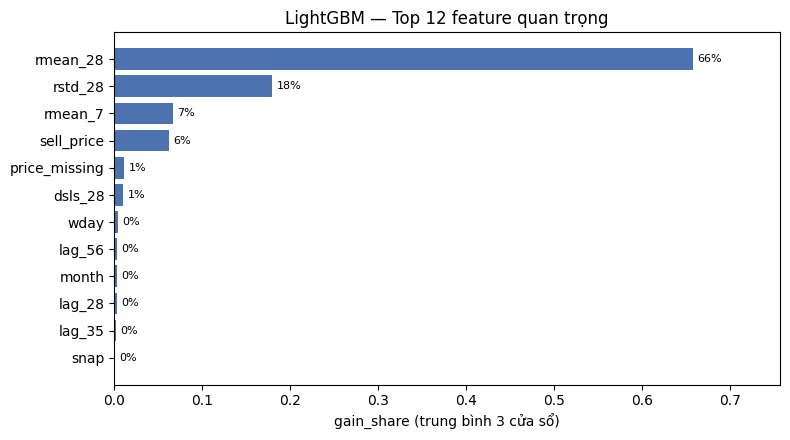

In [13]:
# Biểu đồ 1 — LightGBM: top feature quan trọng (TB 3 cửa sổ)
%matplotlib inline
import matplotlib.pyplot as plt
fi = pd.read_parquet("data/outputs/p3/lgbm_feature_importance.parquet")
top = fi.groupby("feature")["gain_share"].mean().sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color="#4C72B0")
ax.set_xlabel("gain_share (trung bình 3 cửa sổ)")
ax.set_title("LightGBM — Top 12 feature quan trọng")
for i, v in enumerate(top.values[::-1]):
    ax.text(v + 0.005, i, f"{v:.0%}", va="center", fontsize=8)
ax.set_xlim(0, top.max() * 1.15)
fig.tight_layout(); plt.show()

*Nhu cầu gần đây (**rmean_28 ~67%**, rstd_28, rmean_7) chi phối dự báo; lag thô đóng góp nhỏ — hợp lý cho chuỗi bán lẻ.*

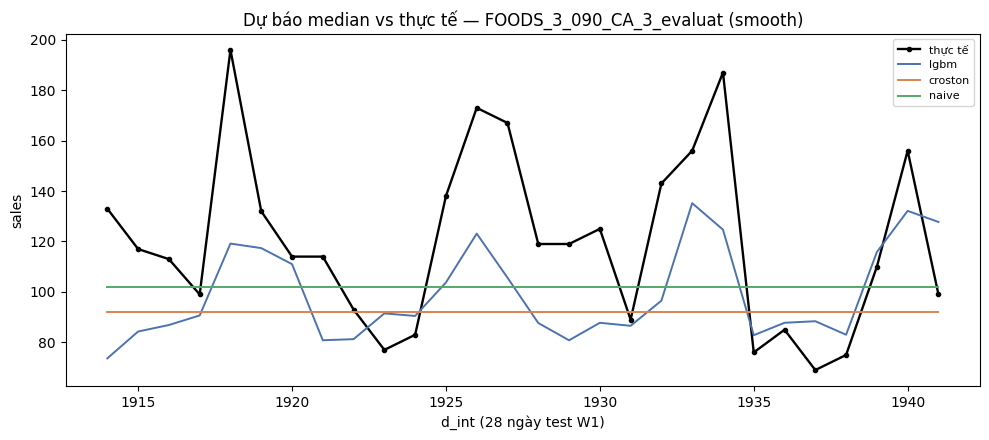

In [14]:
# Biểu đồ 2 — Dự báo median vs thực tế (1 chuỗi smooth, W1): ML vs cổ điển
import matplotlib.pyplot as plt
W1 = (1914, 1941)
dl = pd.read_parquet("data/processed/data_long.parquet", columns=["series_id", "d_int", "sales", "segment"])
sid = dl[dl.segment == "smooth"].groupby("series_id")["sales"].mean().idxmax()
act = dl[(dl.series_id == sid) & (dl.d_int.between(*W1))].sort_values("d_int")
colors = {"lgbm": "#4C72B0", "croston": "#DD8452", "naive": "#55A868"}
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(act.d_int, act.sales, color="black", lw=1.7, marker="o", ms=3, label="thực tế")
for m in ["lgbm", "croston", "naive"]:
    d = pd.read_parquet(f"data/outputs/forecasts/{m}.parquet")
    g = d[(d.series_id == sid) & (d.quantile_level == 0.5) & (d.d_int.between(*W1))].sort_values("d_int")
    ax.plot(g.d_int, g.value, color=colors[m], lw=1.4, label=m)
ax.set_xlabel("d_int (28 ngày test W1)"); ax.set_ylabel("sales")
ax.set_title(f"Dự báo median vs thực tế — {sid[:24]} (smooth)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

*LightGBM bám mùa vụ tuần sát nhất; Croston/Naive cho đường mượt/phẳng hơn (sinh từ điểm rồi bọc NB).*

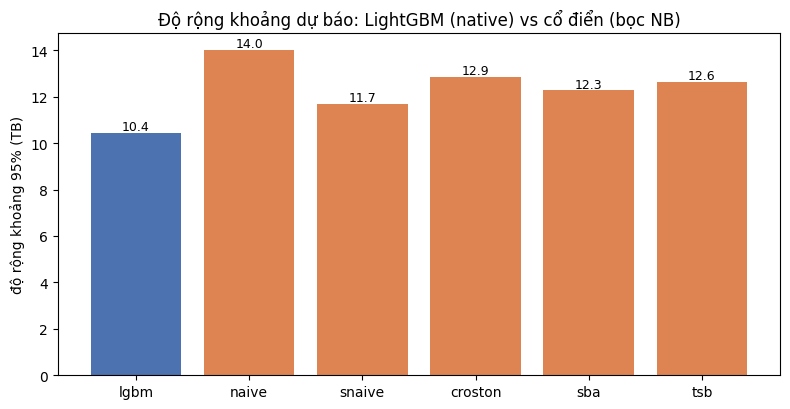

In [15]:
# Biểu đồ 3 — Độ rộng khoảng 95% trung bình theo 6 model của P3
import matplotlib.pyplot as plt
models = ["lgbm", "naive", "snaive", "croston", "sba", "tsb"]
w95 = []
for m in models:
    d = pd.read_parquet(f"data/outputs/forecasts/{m}.parquet", columns=["quantile_level", "value"])
    hi = d.loc[d.quantile_level == 0.975, "value"].mean()
    lo = d.loc[d.quantile_level == 0.025, "value"].mean()
    w95.append(hi - lo)
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(models, w95, color=["#4C72B0"] + ["#DD8452"] * 5)
for b, v in zip(bars, w95):
    ax.text(b.get_x() + b.get_width()/2, v + 0.1, f"{v:.1f}", ha="center", fontsize=9)
ax.set_ylabel("độ rộng khoảng 95% (TB)")
ax.set_title("Độ rộng khoảng dự báo: LightGBM (native) vs cổ điển (bọc NB)")
fig.tight_layout(); plt.show()

*LightGBM (quantile native) cho khoảng **hẹp** hơn; cổ điển bọc-NB **rộng** hơn — khác biệt do lớp bọc, sẽ được P5 hiệu chuẩn (conformal), không phải chênh năng lực.*